# PGHD 분석 예제 노트북

데이터: `ready_to_use_PGHD_50users_variable_sleep_14days.csv`

포함 분석:
1. user별 하루 걸음 수/칼로리 시각화
2. 수면 패턴 분석
3. 활동 패턴 clustering
4. HR 기반 피로도 추정
5. sleep efficiency 분석
6. activity-MET-heart-rate 상관 분석


## 0. 라이브러리 및 데이터 로드

In [1]:
import pandas as pd
import numpy as np

from google.colab import files
uploaded = files.upload()  # 파일 선택창에서 sample.xlsx 업로드

Saving ready_to_use_PGHD_50users_variable_sleep_14days.csv to ready_to_use_PGHD_50users_variable_sleep_14days.csv


In [2]:

import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams['figure.figsize'] = (8,4)

data_path = Path('ready_to_use_PGHD_50users_variable_sleep_14days.csv')
if data_path.exists():
    df = pd.read_csv(data_path, parse_dates=['timestamp'])
    print('데이터 로드 완료:', df.shape)
    display(df.head(10))
else:
    print('ready_to_use_PGHD_50users_14days.csv 파일을 현재 경로에 두고 다시 실행하세요.')

데이터 로드 완료: (100800, 8)


,user_id,timestamp,heart_rate,step_count,sleep_flag,activity_type,MET,calories
0,user_001,2024-01-01 00:00:00,72.2,13,0,sedentary,1.3,15.92
1,user_001,2024-01-01 00:10:00,81.9,8,0,sedentary,1.3,15.92
2,user_001,2024-01-01 00:20:00,71.2,11,0,sedentary,1.3,15.92
3,user_001,2024-01-01 00:30:00,96.2,537,0,walk,3.5,42.88
4,user_001,2024-01-01 00:40:00,71.9,7,0,sedentary,1.3,15.92
5,user_001,2024-01-01 00:50:00,67.3,9,0,sedentary,1.3,15.92
6,user_001,2024-01-01 01:00:00,76.6,1,0,sedentary,1.3,15.92
7,user_001,2024-01-01 01:10:00,133.0,669,0,run,8.0,98.00
8,user_001,2024-01-01 01:20:00,98.2,421,0,walk,3.5,42.88
9,user_001,2024-01-01 01:30:00,68.4,6,0,sedentary,1.3,15.92


## 1. 전처리: 날짜/시간 컬럼 추가

In [4]:
if 'df' in globals():
    df = df.sort_values(['user_id', 'timestamp'])
    df['date'] = df['timestamp'].dt.date
    df['hour'] = df['timestamp'].dt.hour
    df['dayofweek'] = df['timestamp'].dt.dayofweek  # 0=월, 6=일
    display(df.head(20))

,user_id,timestamp,heart_rate,step_count,sleep_flag,activity_type,MET,calories,date,hour,dayofweek
0,user_001,2024-01-01 00:00:00,72.2,13,0,sedentary,1.3,15.92,2024-01-01,0,0
1,user_001,2024-01-01 00:10:00,81.9,8,0,sedentary,1.3,15.92,2024-01-01,0,0
2,user_001,2024-01-01 00:20:00,71.2,11,0,sedentary,1.3,15.92,2024-01-01,0,0
3,user_001,2024-01-01 00:30:00,96.2,537,0,walk,3.5,42.88,2024-01-01,0,0
4,user_001,2024-01-01 00:40:00,71.9,7,0,sedentary,1.3,15.92,2024-01-01,0,0
5,user_001,2024-01-01 00:50:00,67.3,9,0,sedentary,1.3,15.92,2024-01-01,0,0
6,user_001,2024-01-01 01:00:00,76.6,1,0,sedentary,1.3,15.92,2024-01-01,1,0
7,user_001,2024-01-01 01:10:00,133.0,669,0,run,8.0,98.00,2024-01-01,1,0
8,user_001,2024-01-01 01:20:00,98.2,421,0,walk,3.5,42.88,2024-01-01,1,0
9,user_001,2024-01-01 01:30:00,68.4,6,0,sedentary,1.3,15.92,2024-01-01,1,0


## 2. user별 하루 걸음 수 / 칼로리 시각화

In [5]:
!apt-get -y install fonts-nanum
!fc-cache -fv

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 41 not upgraded.
Need to get 10.3 MB of archives.
After this operation, 34.1 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/universe amd64 fonts-nanum all 20200506-1 [10.3 MB]
Fetched 10.3 MB in 1s (8,856 kB/s)
Selecting previously unselected package fonts-nanum.
(Reading database ... 121713 files and directories currently installed.)
Preparing to unpack .../fonts-nanum_20200506-1_all.deb ...
Unpacking fonts-nanum (20200506-1) ...
Setting up fonts-nanum (20200506-1) ...
Processing triggers for fontconfig (2.13.1-4.2ubuntu5) ...
/usr/share/fonts: caching, new cache contents: 0 fonts, 1 dirs
/usr/share/fonts/truetype: caching, new cache contents: 0 fonts, 3 dirs
/usr/share/fonts/truetype/humor-sans: caching, new cache contents: 1 fonts, 0 dirs
/usr

In [ ]:
plt.rc('font', family='DejaVu Sans')
plt.rcParams['axes.unicode_minus'] = False

/tmp/ipython-input-2151840359.py:17: UserWarning: Glyph 54616 (\N{HANGUL SYLLABLE HA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-2151840359.py:17: UserWarning: Glyph 47336 (\N{HANGUL SYLLABLE RU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-2151840359.py:17: UserWarning: Glyph 44152 (\N{HANGUL SYLLABLE GEOL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-2151840359.py:17: UserWarning: Glyph 51020 (\N{HANGUL SYLLABLE EUM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-2151840359.py:17: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-2151840359.py:17: UserWarning: Glyph 52628 (\N{HANGUL SYLLABLE CU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-2151840359.py:17: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr

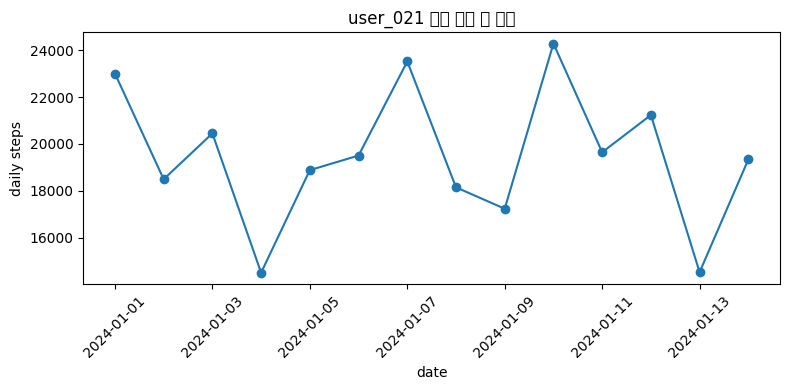

/tmp/ipython-input-2151840359.py:26: UserWarning: Glyph 54616 (\N{HANGUL SYLLABLE HA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-2151840359.py:26: UserWarning: Glyph 47336 (\N{HANGUL SYLLABLE RU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-2151840359.py:26: UserWarning: Glyph 52860 (\N{HANGUL SYLLABLE KAL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-2151840359.py:26: UserWarning: Glyph 47196 (\N{HANGUL SYLLABLE RO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-2151840359.py:26: UserWarning: Glyph 47532 (\N{HANGUL SYLLABLE RI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-2151840359.py:26: UserWarning: Glyph 49548 (\N{HANGUL SYLLABLE SO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-2151840359.py:26: UserWarning: Glyph 47784 (\N{HANGUL SYLLABLE MO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/

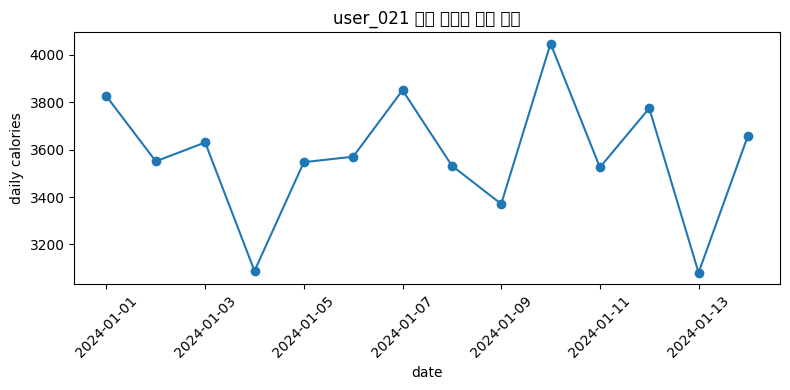

In [7]:
if 'df' in globals():
    daily = df.groupby(['user_id', 'date']).agg(
        daily_steps=('step_count', 'sum'),
        daily_calories=('calories', 'sum')
    ).reset_index()

    # 한 명의 예시 유저만 선택해서 시각화 (user_001)
    user_example = 'user_021'
    daily_u = daily[daily['user_id'] == user_example]

    fig, ax1 = plt.subplots()
    ax1.plot(daily_u['date'], daily_u['daily_steps'], marker='o')
    ax1.set_xlabel('date')
    ax1.set_ylabel('daily steps')
    ax1.set_title(f'{user_example} 하루 걸음 수 추이')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    fig, ax2 = plt.subplots()
    ax2.plot(daily_u['date'], daily_u['daily_calories'], marker='o')
    ax2.set_xlabel('date')
    ax2.set_ylabel('daily calories')
    ax2.set_title(f'{user_example} 하루 칼로리 소모 추이')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


## 3. 수면 패턴 분석
- 사용자별 평균 수면 시간
- 시간대별 수면 비율(전체 집단 기준)

/tmp/ipython-input-1909066588.py:15: UserWarning: Glyph 54217 (\N{HANGUL SYLLABLE PYEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-1909066588.py:15: UserWarning: Glyph 44512 (\N{HANGUL SYLLABLE GYUN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-1909066588.py:15: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-1909066588.py:15: UserWarning: Glyph 47732 (\N{HANGUL SYLLABLE MYEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-1909066588.py:15: UserWarning: Glyph 49884 (\N{HANGUL SYLLABLE SI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-1909066588.py:15: UserWarning: Glyph 44036 (\N{HANGUL SYLLABLE GAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-1909066588.py:15: UserWarning: Glyph 48516 (\N{HANGUL SYLLABLE BUN}) missing from font(s) DejaVu Sans.
  plt.tight_layo

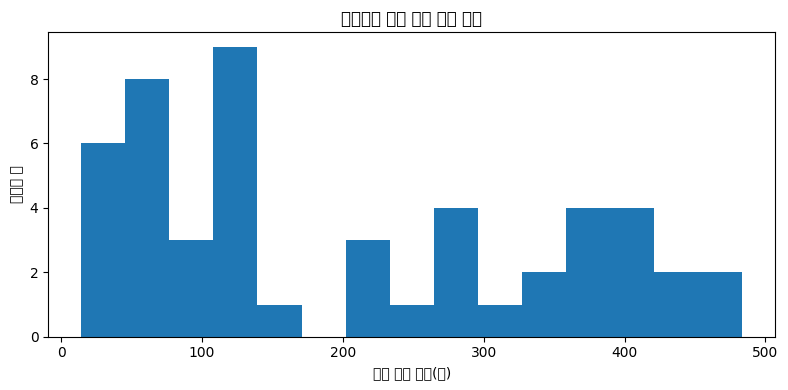

/tmp/ipython-input-1909066588.py:26: UserWarning: Glyph 49884 (\N{HANGUL SYLLABLE SI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-1909066588.py:26: UserWarning: Glyph 44033 (\N{HANGUL SYLLABLE GAG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-1909066588.py:26: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-1909066588.py:26: UserWarning: Glyph 47732 (\N{HANGUL SYLLABLE MYEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-1909066588.py:26: UserWarning: Glyph 48708 (\N{HANGUL SYLLABLE BI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-1909066588.py:26: UserWarning: Glyph 50984 (\N{HANGUL SYLLABLE YUL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-1909066588.py:26: UserWarning: Glyph 44036 (\N{HANGUL SYLLABLE GAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


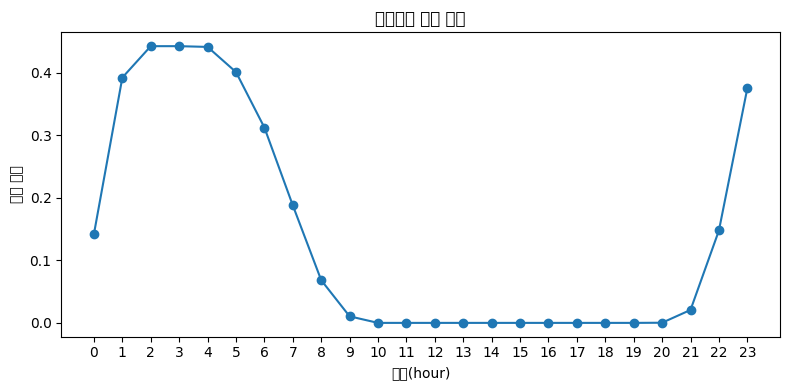

In [8]:
if 'df' in globals():
    # 하루 수면 시간(분) 계산: 10분 간격이므로 sleep_flag * 10분
    sleep_daily = df.groupby(['user_id', 'date']).agg(
        sleep_flags=('sleep_flag', 'sum')
    ).reset_index()
    sleep_daily['sleep_minutes'] = sleep_daily['sleep_flags'] * 10

    # 사용자별 평균 수면 시간
    sleep_user_mean = sleep_daily.groupby('user_id')['sleep_minutes'].mean()
    plt.figure()
    sleep_user_mean.plot(kind='hist', bins=15)
    plt.xlabel('평균 수면 시간(분)')
    plt.ylabel('사용자 수')
    plt.title('사용자별 평균 수면 시간 분포')
    plt.tight_layout()
    plt.show()

    # 시간대별 수면 비율 (집단 전체)
    hour_sleep = df.groupby('hour')['sleep_flag'].mean()
    plt.figure()
    hour_sleep.plot(marker='o')
    plt.xlabel('시각(hour)')
    plt.ylabel('수면 비율')
    plt.title('시간대별 수면 비율')
    plt.xticks(range(0,24))
    plt.tight_layout()
    plt.show()


## 4. 활동 패턴 clustering
- user × day 기준으로 일일 활동 요약 feature 생성
- K-means로 클러스터링 (단순 예시)

※ sklearn 사용 (시각화용 2~3개 feature만 사용)

/tmp/ipython-input-1990465074.py:24: UserWarning: Glyph 54876 (\N{HANGUL SYLLABLE HWAL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-1990465074.py:24: UserWarning: Glyph 46041 (\N{HANGUL SYLLABLE DONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-1990465074.py:24: UserWarning: Glyph 54056 (\N{HANGUL SYLLABLE PAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-1990465074.py:24: UserWarning: Glyph 53556 (\N{HANGUL SYLLABLE TEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-1990465074.py:24: UserWarning: Glyph 53364 (\N{HANGUL SYLLABLE KEUL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-1990465074.py:24: UserWarning: Glyph 47084 (\N{HANGUL SYLLABLE REO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-1990465074.py:24: UserWarning: Glyph 49828 (\N{HANGUL SYLLABLE SEU}) missing from font(s) DejaVu Sans.
  plt.tight_layo

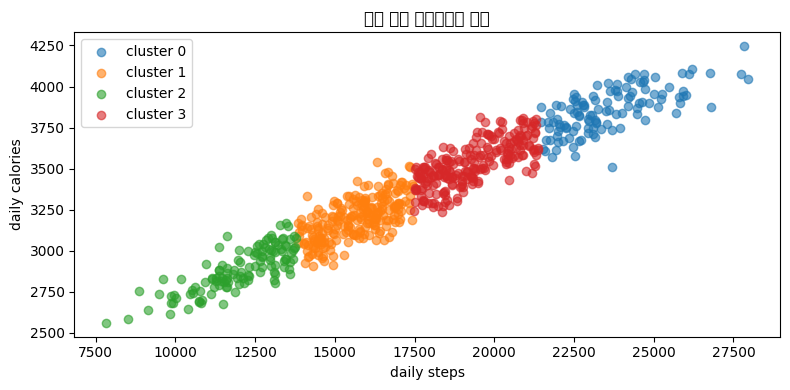

In [10]:
from sklearn.cluster import KMeans

if 'df' in globals():
    daily_feat = df.groupby(['user_id', 'date']).agg(
        daily_steps=('step_count', 'sum'),
        daily_calories=('calories', 'sum'),
        mean_hr=('heart_rate', 'mean')
    ).reset_index()

    X = daily_feat[['daily_steps', 'daily_calories', 'mean_hr']].values

    kmeans = KMeans(n_clusters=4, random_state=42)
    daily_feat['cluster'] = kmeans.fit_predict(X)

    # 단순 시각화: daily_steps vs daily_calories
    plt.figure()
    for c in sorted(daily_feat['cluster'].unique()):
        tmp = daily_feat[daily_feat['cluster'] == c]
        plt.scatter(tmp['daily_steps'], tmp['daily_calories'], label=f'cluster {c}', alpha=0.6)
    plt.xlabel('daily steps')
    plt.ylabel('daily calories')
    plt.title('활동 패턴 클러스터링 결과')
    plt.legend()
    plt.tight_layout()
    plt.show()

    daily_feat.head()

## 5. HR 기반 피로도 추정
- 단순 예시: resting HR(야간) 상승 + 일일 평균 HR 증가 → 피로도 ↑ 라고 가정
- user × day 기준으로 "피로 점수" 합성

/tmp/ipython-input-2084199831.py:30: UserWarning: Glyph 44592 (\N{HANGUL SYLLABLE GI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-2084199831.py:30: UserWarning: Glyph 48152 (\N{HANGUL SYLLABLE BAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-2084199831.py:30: UserWarning: Glyph 54588 (\N{HANGUL SYLLABLE PI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-2084199831.py:30: UserWarning: Glyph 47196 (\N{HANGUL SYLLABLE RO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-2084199831.py:30: UserWarning: Glyph 46020 (\N{HANGUL SYLLABLE DO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-2084199831.py:30: UserWarning: Glyph 52628 (\N{HANGUL SYLLABLE CU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-2084199831.py:30: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/t

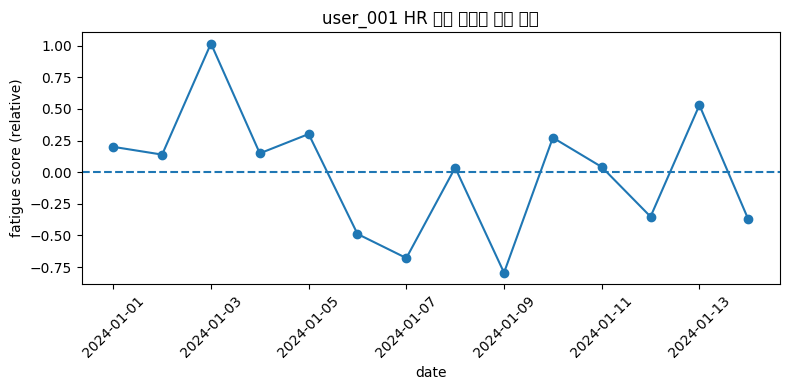

In [11]:
if 'df' in globals():
    # 야간(0~5시) HR 평균을 resting_hr_night로 정의
    night_mask = df['hour'].between(0,5)
    night_hr = df[night_mask].groupby(['user_id', 'date'])['heart_rate'].mean().reset_index(name='resting_hr_night')

    daily_hr = df.groupby(['user_id', 'date'])['heart_rate'].mean().reset_index(name='avg_hr')

    fatigue = pd.merge(daily_hr, night_hr, on=['user_id', 'date'], how='left')

    # 사용자별 기준 resting HR 계산
    baseline_rest = fatigue.groupby('user_id')['resting_hr_night'].transform('mean')
    fatigue['delta_resting'] = fatigue['resting_hr_night'] - baseline_rest

    # 피로 점수(예시): delta_resting + (avg_hr - 사용자별 avg_hr_baseline)
    baseline_avg_hr = fatigue.groupby('user_id')['avg_hr'].transform('mean')
    fatigue['delta_avg_hr'] = fatigue['avg_hr'] - baseline_avg_hr

    fatigue['fatigue_score'] = fatigue['delta_resting']/5.0 + fatigue['delta_avg_hr']/5.0

    # 예시 사용자 시각화
    u_example = 'user_001'
    f_u = fatigue[fatigue['user_id'] == u_example]
    plt.figure()
    plt.plot(f_u['date'], f_u['fatigue_score'], marker='o')
    plt.axhline(0, linestyle='--')
    plt.xlabel('date')
    plt.ylabel('fatigue score (relative)')
    plt.title(f'{u_example} HR 기반 피로도 추정 추이')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    fatigue.head()

## 6. Sleep efficiency 분석
- 하루에 수면으로 보낸 구간 비율을 sleep efficiency라고 가정
- user별 평균 sleep efficiency 분포 확인

/tmp/ipython-input-3515018689.py:16: UserWarning: Glyph 54217 (\N{HANGUL SYLLABLE PYEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-3515018689.py:16: UserWarning: Glyph 44512 (\N{HANGUL SYLLABLE GYUN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-3515018689.py:16: UserWarning: Glyph 49324 (\N{HANGUL SYLLABLE SA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-3515018689.py:16: UserWarning: Glyph 50857 (\N{HANGUL SYLLABLE YONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-3515018689.py:16: UserWarning: Glyph 51088 (\N{HANGUL SYLLABLE JA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-3515018689.py:16: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-3515018689.py:16: UserWarning: Glyph 48324 (\N{HANGUL SYLLABLE BYEOL}) missing from font(s) DejaVu Sans.
  plt.tight_layo

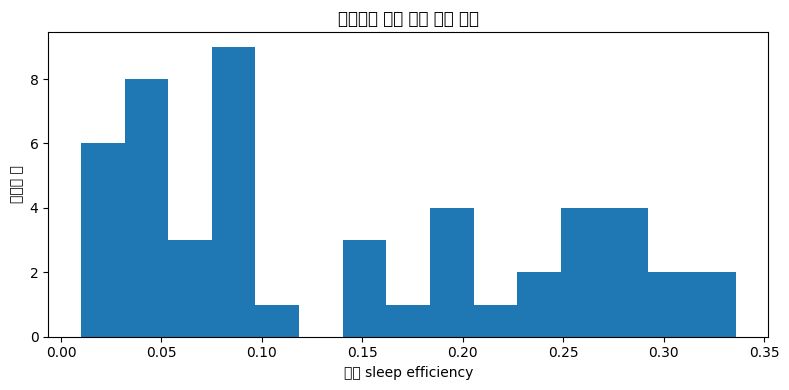

In [12]:
if 'df' in globals():
    # 일 단위 수면 효율: sleep_flag 1 비율
    sleep_eff = df.groupby(['user_id', 'date']).agg(
        sleep_flags=('sleep_flag', 'sum'),
        total_records=('sleep_flag', 'count')
    ).reset_index()
    sleep_eff['sleep_efficiency'] = sleep_eff['sleep_flags'] / sleep_eff['total_records']

    # 사용자별 평균 sleep efficiency
    sleep_eff_user = sleep_eff.groupby('user_id')['sleep_efficiency'].mean().reset_index()
    plt.figure()
    plt.hist(sleep_eff_user['sleep_efficiency'], bins=15)
    plt.xlabel('평균 sleep efficiency')
    plt.ylabel('사용자 수')
    plt.title('사용자별 평균 수면 효율 분포')
    plt.tight_layout()
    plt.show()

    sleep_eff_user.head()

## 7. activity - MET - heart_rate 상관 분석
- 활동 수준과 에너지 소모, HR 간의 상관관계
- 전체 데이터 기준 상관계수 및 간단 scatter plot

MET가 높을수록 심박수가 높아지는 아주 정상적인 생리적 패턴을 보여준다.

상관계수 행렬:


,heart_rate,step_count,MET,calories
heart_rate,1.000000,0.873765,0.926388,0.926401
step_count,0.873765,1.000000,0.939803,0.939832
MET,0.926388,0.939803,1.000000,1.000000
calories,0.926401,0.939832,1.000000,1.000000


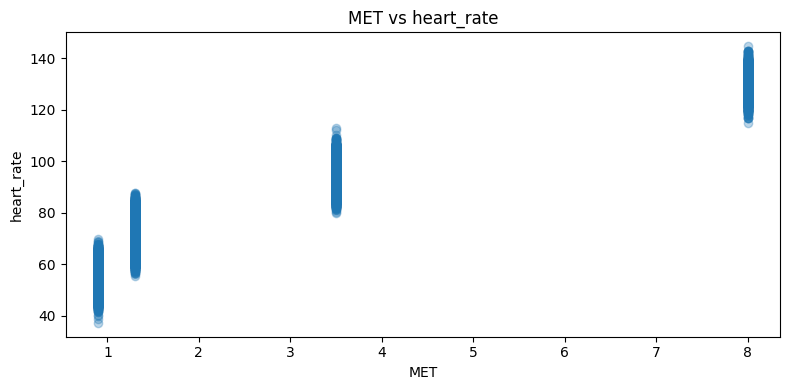

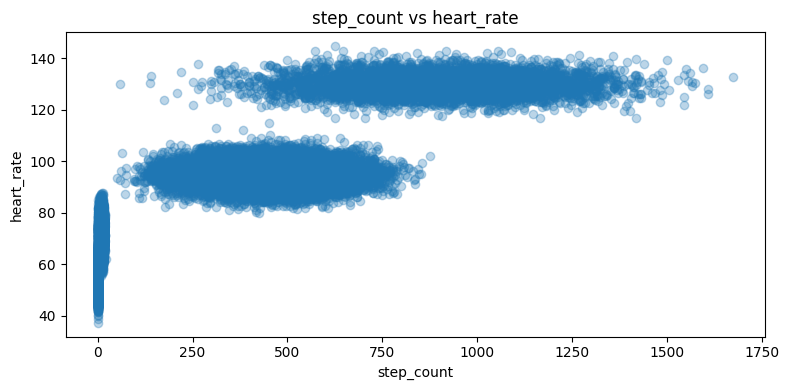

In [13]:
if 'df' in globals():
    corr_cols = ['heart_rate', 'step_count', 'MET', 'calories']
    corr = df[corr_cols].corr()
    print('상관계수 행렬:')
    display(corr)

    # heart_rate vs MET 산점도
    plt.figure()
    plt.scatter(df['MET'], df['heart_rate'], alpha=0.3)
    plt.xlabel('MET')
    plt.ylabel('heart_rate')
    plt.title('MET vs heart_rate')
    plt.tight_layout()
    plt.show()

    # step_count vs heart_rate 산점도
    plt.figure()
    plt.scatter(df['step_count'], df['heart_rate'], alpha=0.3)
    plt.xlabel('step_count')
    plt.ylabel('heart_rate')
    plt.title('step_count vs heart_rate')
    plt.tight_layout()
    plt.show()
